## Data Preprocessing & Train/Test Split

In [37]:
import pandas as pd
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.optim as optim
import seaborn as sns
from scipy.stats import wasserstein_distance

In [8]:
# --- 1. CONFIGURATION ---
MESSAGE_FILE = "MSFT_2012-06-21_34200000_57600000_message_10.csv"
ORDERBOOK_FILE = "MSFT_2012-06-21_34200000_57600000_orderbook_10.csv" # Assuming you have this
DT = 10.0 # 10 seconds
K_LEVELS = 3
NORMALIZATION_CONSTANT = 100.0 # 'c' from the paper to scale data into a reasonable range

In [10]:
# --- 2. LOBSTER DATA LOADING ---
def load_and_preprocess_lobster(msg_file, ob_file, dt=10.0, k=3):
    # Load messages (for timestamps) and orderbook
    msg_cols = ['Time', 'Type', 'OrderID', 'Size', 'Price', 'Direction']
    messages = pd.read_csv(msg_file, names=msg_cols)
    
    # Orderbook columns: AskPrice1, AskSize1, BidPrice1, BidSize1, ...
    ob_cols = []
    for i in range(1, 11): # Assuming level 10 data
        ob_cols.extend([f'AskPrice{i}', f'AskSize{i}', f'BidPrice{i}', f'BidSize{i}'])
    orderbook = pd.read_csv(ob_file, names=ob_cols)
    
    # Combine time with orderbook
    df = pd.concat([messages[['Time']], orderbook], axis=1)
    
    # Filter out first and last 30 mins of the trading day (Trading hours: 34200s to 57600s)
    # 9:30 AM = 34200s, 4:00 PM = 57600s. 
    # +30 mins = 36000s, -30 mins = 55800s
    df = df[(df['Time'] >= 36000) & (df['Time'] <= 55800)]
    
    # Sample at regular dt intervals
    # Create bins every dt seconds and take the last observation in each bin
    df['TimeBin'] = (df['Time'] // dt) * dt
    sampled_df = df.drop_duplicates(subset=['TimeBin'], keep='last').copy()
    
    # Extract centered queue sizes: [Bid_k, ..., Bid_1, Ask_1, ..., Ask_k]
    # As per the paper: Bids are negative, Asks are positive
    state_vectors = []
    for _, row in sampled_df.iterrows():
        # Bids (k to 1) -> negative
        bids = [-row[f'BidSize{i}'] for i in range(k, 0, -1)]
        # Asks (1 to k) -> positive
        asks = [row[f'AskSize{i}'] for i in range(1, k + 1)]
        state_vectors.append(bids + asks)
        
    states_np = np.array(state_vectors)
    
    # Normalize: sign(Q) * sqrt(|Q|) / c
    normalized_states = np.sign(states_np) * np.sqrt(np.abs(states_np)) / NORMALIZATION_CONSTANT
    return normalized_states

In [12]:
# --- 3. CREATE TRANSITIONS & SPLIT ---
print("Preprocessing data...")
try:
    data = load_and_preprocess_lobster(MESSAGE_FILE, ORDERBOOK_FILE, dt=DT, k=K_LEVELS)
    
    # Create (S_t, X_{t+dt}) pairs
    S_t = data[:-1]
    X_next = data[1:]
    
    # Split into 80% train, 20% test (Chronological split is important for time-series)
    split_idx = int(len(S_t) * 0.8)
    
    train_S = torch.tensor(S_t[:split_idx], dtype=torch.float32)
    train_X = torch.tensor(X_next[:split_idx], dtype=torch.float32)
    
    test_S = torch.tensor(S_t[split_idx:], dtype=torch.float32)
    test_X = torch.tensor(X_next[split_idx:], dtype=torch.float32)
    
    print(f"Train samples: {len(train_S)}, Test samples: {len(test_S)}")
except Exception as e:
    print(f"Error loading data (ensure both msg and ob files are present): {e}")

Preprocessing data...
Train samples: 1583, Test samples: 396


## PyTorch Dataset and DataLoader

In [15]:
class LOBDataset(Dataset):
    def __init__(self, states, next_states):
        self.states = states
        self.next_states = next_states
        
    def __len__(self):
        return len(self.states)
        
    def __getitem__(self, idx):
        return self.states[idx], self.next_states[idx]

BATCH_SIZE = 64

train_dataset = LOBDataset(train_S, train_X)
test_dataset = LOBDataset(test_S, test_X)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

## WGAN-GP Architectures

In [18]:
class Generator(nn.Module):
    def __init__(self, noise_dim, state_dim, hidden_dim=64, output_dim=6):
        super(Generator, self).__init__()
        # Noise branch
        self.noise_branch = nn.Sequential(
            nn.Linear(noise_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU()
        )
        # State branch
        self.state_branch = nn.Sequential(
            nn.Linear(state_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU()
        )
        # Concat branch
        self.concat_branch = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, output_dim) # Linear activation to allow pos/neg queues
        )

    def forward(self, z, s):
        hz = self.noise_branch(z)
        hs = self.state_branch(s)
        h_concat = torch.cat([hz, hs], dim=1)
        return self.concat_branch(h_concat)

In [20]:
class Critic(nn.Module):
    def __init__(self, target_dim, state_dim, hidden_dim=64):
        super(Critic, self).__init__()
        input_dim = target_dim + state_dim
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, x, s):
        h = torch.cat([x, s], dim=1)
        return self.network(h)

## Training Loop 

In [23]:
def compute_gradient_penalty(critic, real_samples, fake_samples, conditions, device):
    alpha = torch.rand((real_samples.size(0), 1)).to(device)
    interpolates = (alpha * real_samples + ((1 - alpha) * fake_samples)).requires_grad_(True)
    d_interpolates = critic(interpolates, conditions)
    fake_grad = torch.ones(d_interpolates.size()).to(device)
    
    gradients = torch.autograd.grad(
        outputs=d_interpolates, inputs=interpolates,
        grad_outputs=fake_grad, create_graph=True,
        retain_graph=True, only_inputs=True
    )[0]
    gradients = gradients.view(gradients.size(0), -1)
    gradient_penalty = ((gradients.norm(2, dim=1) - 1) ** 2).mean()
    return gradient_penalty

In [29]:
def train_gan(train_loader, test_loader, epochs=1000, noise_dim=10, state_dim=6, lambda_gp=10, clip_value=0.01):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    generator = Generator(noise_dim, state_dim).to(device)
    critic = Critic(state_dim, state_dim).to(device)
    
    opt_G = optim.Adam(generator.parameters(), lr=1e-5)
    opt_C = optim.Adam(critic.parameters(), lr=1e-5)
    
    train_c_losses, test_w1_distances = [], []

    print("Starting Training...")
    for epoch in range(epochs):
        generator.train()
        critic.train()
        epoch_c_loss = 0
        
        for batch_states, batch_next_states in train_loader:
            batch_states, batch_next_states = batch_states.to(device), batch_next_states.to(device)
            batch_size = batch_states.size(0)
            
            # --- Train Critic ---
            for _ in range(3): # Train critic more often than generator
                opt_C.zero_grad()
                z = torch.randn(batch_size, noise_dim).to(device)
                fake_next_states = generator(z, batch_states)
                
                real_validity = critic(batch_next_states, batch_states)
                fake_validity = critic(fake_next_states.detach(), batch_states)
                gp = compute_gradient_penalty(critic, batch_next_states, fake_next_states.detach(), batch_states, device)
                
                d_loss = -torch.mean(real_validity) + torch.mean(fake_validity) + lambda_gp * gp
                d_loss.backward()
                torch.nn.utils.clip_grad_value_(critic.parameters(), clip_value)
                opt_C.step()
                epoch_c_loss += d_loss.item()
            
            # --- Train Generator ---
            opt_G.zero_grad()
            z = torch.randn(batch_size, noise_dim).to(device)
            fake_next_states = generator(z, batch_states)
            fake_validity = critic(fake_next_states, batch_states)
            
            g_loss = -torch.mean(fake_validity)
            g_loss.backward()
            opt_G.step()

        # --- Evaluation on Test Set ---
        if epoch % 100 == 0:
            generator.eval()
            critic.eval()
            with torch.no_grad():
                test_w1 = 0
                for test_s, test_x in test_loader:
                    test_s, test_x = test_s.to(device), test_x.to(device)
                    z = torch.randn(test_s.size(0), noise_dim).to(device)
                    fake_x = generator(z, test_s)
                    
                    real_val = critic(test_x, test_s).mean()
                    fake_val = critic(fake_x, test_s).mean()
                    # Approx W1 Distance = E[Critic(Real)] - E[Critic(Fake)]
                    test_w1 += (real_val - fake_val).item()
                
                test_w1 /= len(test_loader)
                print(f"Epoch {epoch}/{epochs} | Approx W1 Distance (Test): {test_w1:.4f}")
                test_w1_distances.append(test_w1)

    return generator, test_w1_distances

# Run Training (Set epochs lower if you just want to test if it runs)
NOISE_DIM = 10
trained_generator, w1_history = train_gan(train_loader, test_loader, epochs=20000, noise_dim=NOISE_DIM)

Starting Training...
Epoch 0/20000 | Approx W1 Distance (Test): 0.0176
Epoch 100/20000 | Approx W1 Distance (Test): -1.6915
Epoch 200/20000 | Approx W1 Distance (Test): 0.1818
Epoch 300/20000 | Approx W1 Distance (Test): 0.3819
Epoch 400/20000 | Approx W1 Distance (Test): 0.0150
Epoch 500/20000 | Approx W1 Distance (Test): -0.2039
Epoch 600/20000 | Approx W1 Distance (Test): 0.1989
Epoch 700/20000 | Approx W1 Distance (Test): -0.0899
Epoch 800/20000 | Approx W1 Distance (Test): -0.0182
Epoch 900/20000 | Approx W1 Distance (Test): -0.0331
Epoch 1000/20000 | Approx W1 Distance (Test): -0.0462
Epoch 1100/20000 | Approx W1 Distance (Test): -0.1412
Epoch 1200/20000 | Approx W1 Distance (Test): 0.1382
Epoch 1300/20000 | Approx W1 Distance (Test): -0.1626
Epoch 1400/20000 | Approx W1 Distance (Test): -0.0427
Epoch 1500/20000 | Approx W1 Distance (Test): -0.2881
Epoch 1600/20000 | Approx W1 Distance (Test): 1.0086
Epoch 1700/20000 | Approx W1 Distance (Test): 0.4514
Epoch 1800/20000 | Approx W

In [31]:
def point_reflect_lob(state):
    # Flips the state [Bid3, Bid2, Bid1, Ask1, Ask2, Ask3] 
    # to [-Ask3, -Ask2, -Ask1, -Bid1, -Bid2, -Bid3]
    return -torch.flip(state, dims=[1])

def generate_symmetric_step(generator, z, current_state):
    p = np.random.rand()
    if p < 0.5:
        return generator(z, current_state)
    else:
        reflected_state = point_reflect_lob(current_state)
        generated_reflected = generator(z, reflected_state)
        return point_reflect_lob(generated_reflected)

def simulate_paths(generator, initial_state, num_steps, num_paths, noise_dim):
    device = next(generator.parameters()).device
    initial_state = initial_state.to(device).unsqueeze(0).repeat(num_paths, 1)
    
    paths = [initial_state.cpu().detach().numpy()]
    current_state = initial_state
    
    generator.eval()
    with torch.no_grad():
        for _ in range(num_steps):
            z = torch.randn(num_paths, noise_dim).to(device)
            next_state = generate_symmetric_step(generator, z, current_state)
            paths.append(next_state.cpu().numpy())
            current_state = next_state
            
    # Shape: [num_steps + 1, num_paths, state_dim]
    return np.array(paths)

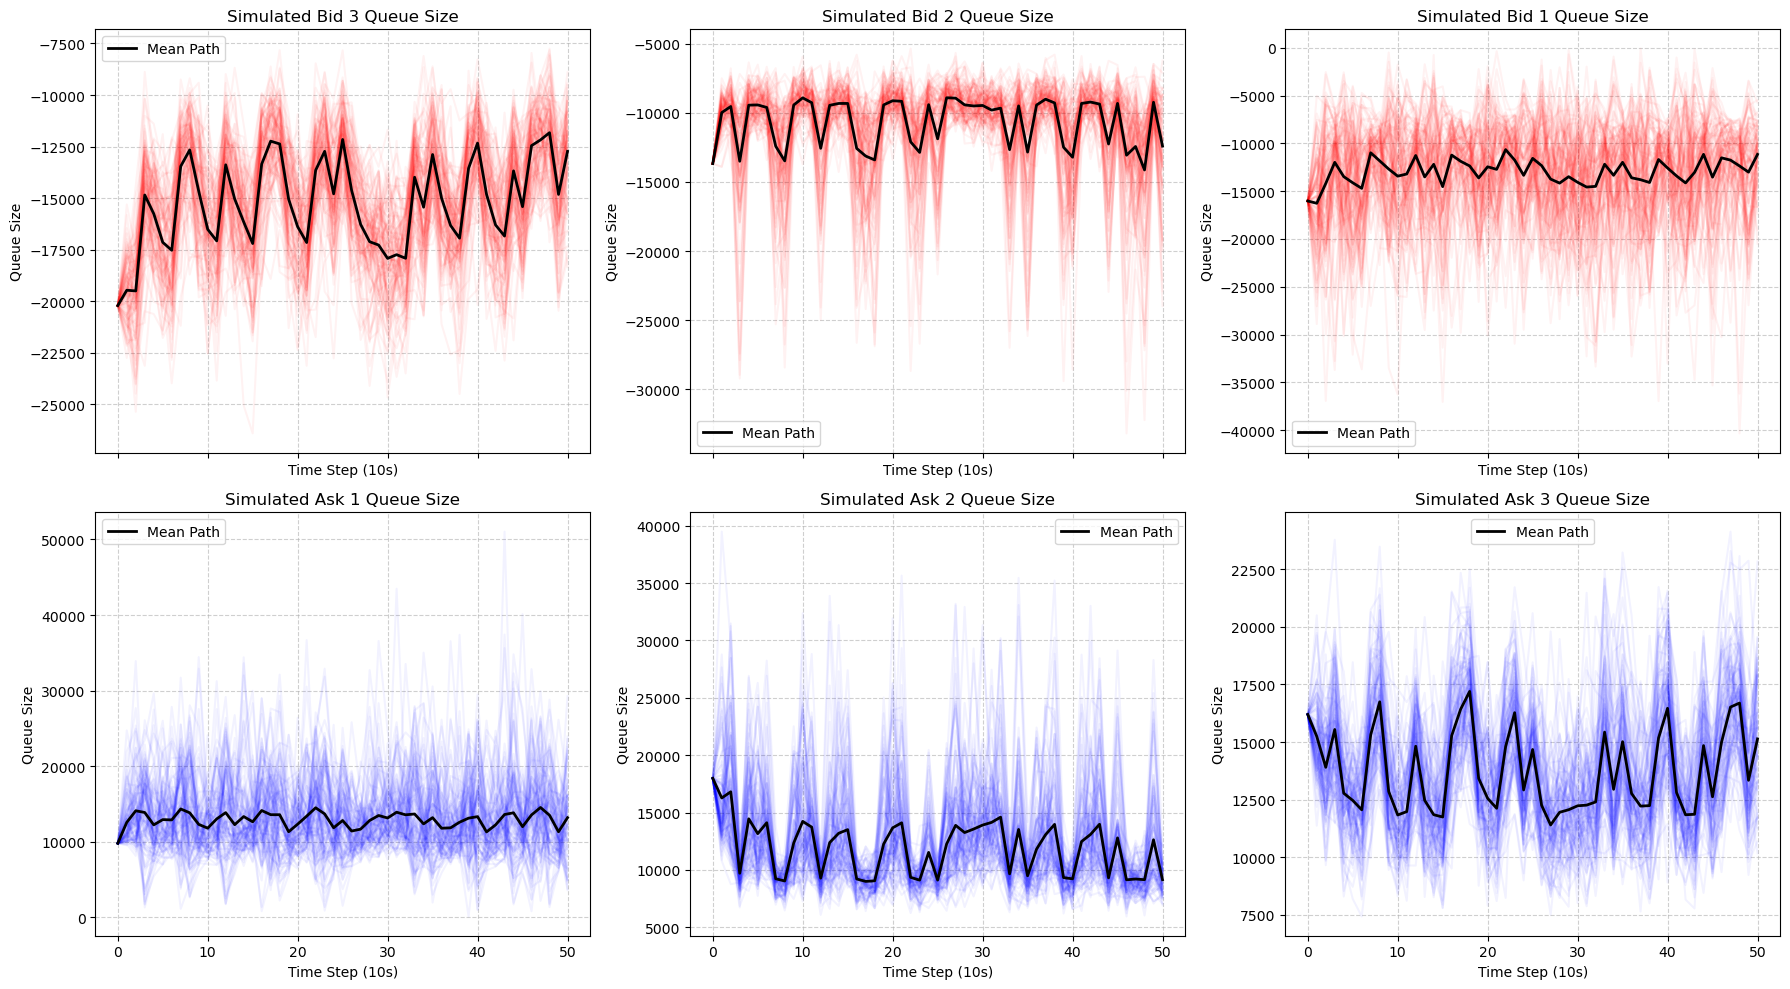

In [33]:
# Let's pick the very first state from the test set as our seed
initial_seed_state = test_S[0]

# Simulate 100 paths for 50 steps
simulated_paths = simulate_paths(trained_generator, initial_seed_state, num_steps=50, num_paths=100, noise_dim=NOISE_DIM)

# 1. Denormalize ALL levels at once
# Formula: Q = sign(Q_tilde) * (abs(Q_tilde) * c)**2
denormalized_paths = np.sign(simulated_paths) * (np.abs(simulated_paths) * NORMALIZATION_CONSTANT)**2

# 2. Setup labels and colors for the 6 levels
# Index mapping: 0=Bid3, 1=Bid2, 2=Bid1, 3=Ask1, 4=Ask2, 5=Ask3
labels = ['Bid 3', 'Bid 2', 'Bid 1', 'Ask 1', 'Ask 2', 'Ask 3']
# Bids are typically represented in red (negative queues), Asks in blue (positive queues)
colors = ['red', 'red', 'red', 'blue', 'blue', 'blue'] 

# 3. Create a 2x3 grid of subplots
fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharex=True)
axes = axes.flatten()

for idx in range(6):
    ax = axes[idx]
    # Extract data for this specific level across all time steps and paths
    level_data = denormalized_paths[:, :, idx]
    
    # Plot all 100 individual paths with a low opacity
    for p in range(level_data.shape[1]): 
        ax.plot(level_data[:, p], alpha=0.05, color=colors[idx])
        
    # Calculate and plot the mean path in black to make it stand out
    mean_path = np.mean(level_data, axis=1)
    ax.plot(mean_path, color='black', linewidth=2, label='Mean Path')
    
    ax.set_title(f"Simulated {labels[idx]} Queue Size")
    ax.set_xlabel("Time Step (10s)")
    ax.set_ylabel("Queue Size")
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend()

# Adjust layout to prevent overlap and display the plot
plt.tight_layout()
plt.show()

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before opera

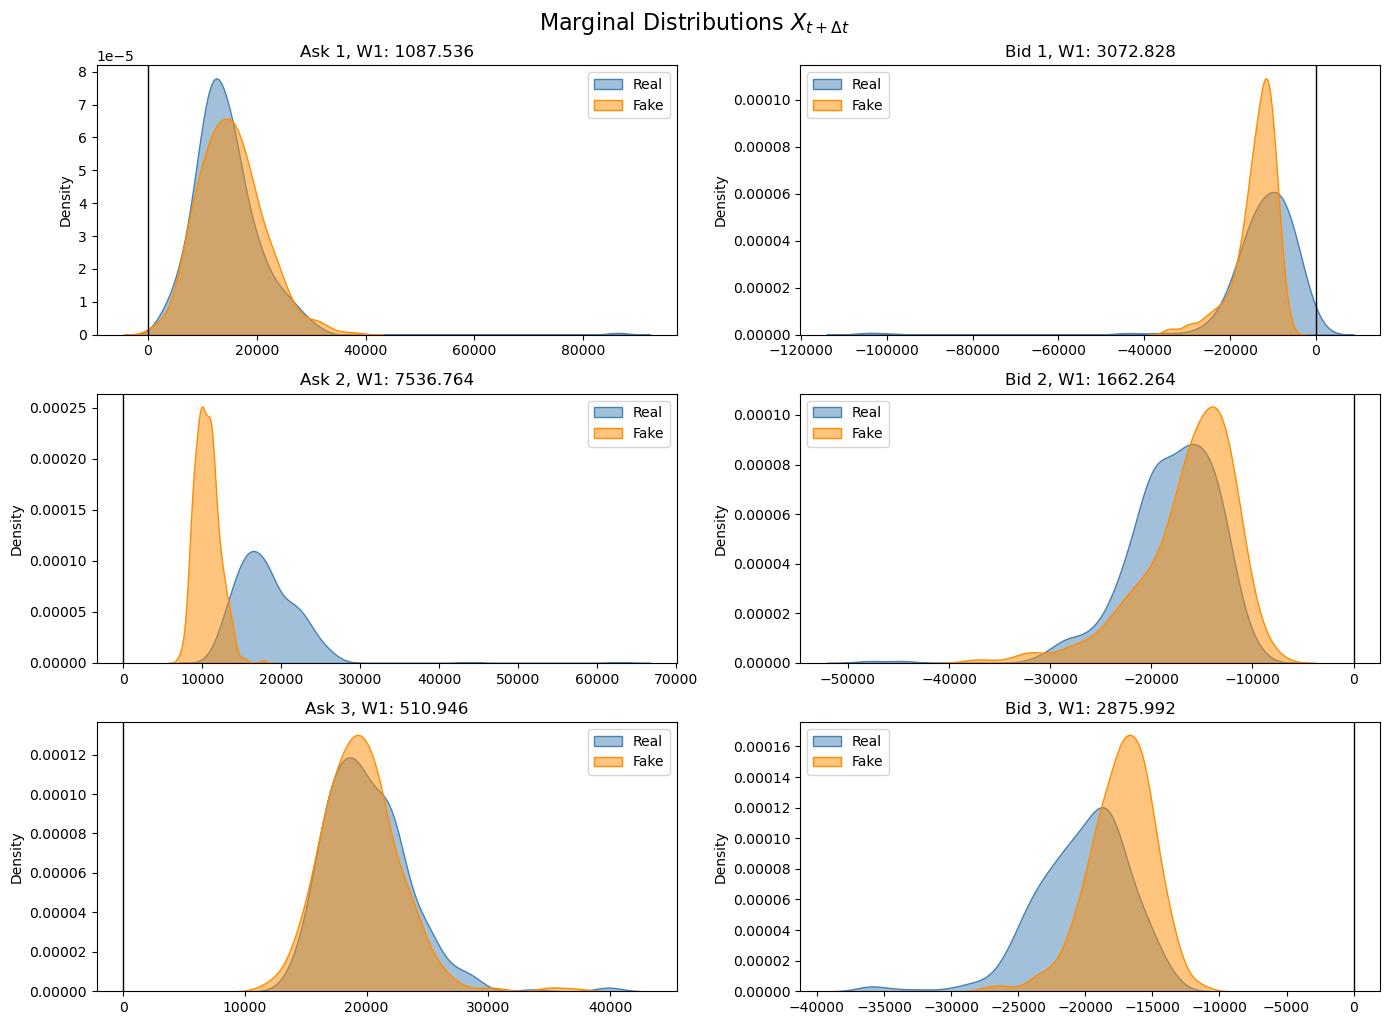

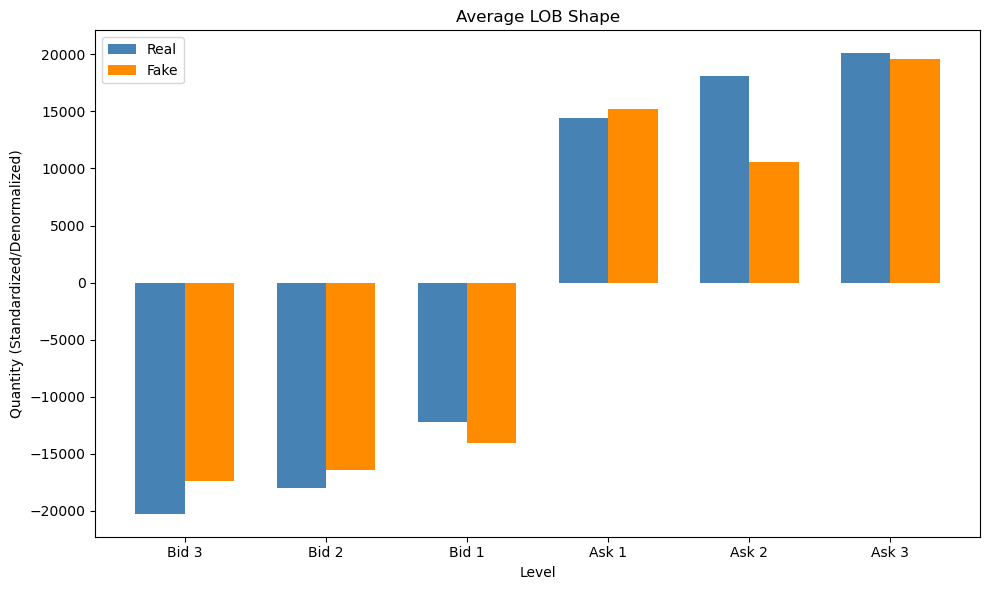

In [39]:
# --- 1. GENERATE FAKE SAMPLES FOR THE ENTIRE TEST SET ---
device = next(trained_generator.parameters()).device
trained_generator.eval()

# We will use standard generation for the 1-step marginals evaluation 
# (Symmetric generation is primarily for long multi-step price paths)
with torch.no_grad():
    z_test = torch.randn(len(test_S), NOISE_DIM).to(device)
    test_S_device = test_S.to(device)
    fake_X_normalized = trained_generator(z_test, test_S_device).cpu().numpy()

real_X_normalized = test_X.numpy()

# --- 2. DENORMALIZE THE DATA ---
def denormalize(Q_tilde, c=NORMALIZATION_CONSTANT):
    return np.sign(Q_tilde) * (np.abs(Q_tilde) * c)**2

real_X = denormalize(real_X_normalized)
fake_X = denormalize(fake_X_normalized)

# Index mapping based on the state vector: [Bid3, Bid2, Bid1, Ask1, Ask2, Ask3]
# To match the paper's visual layout, we will pair them: Ask1/Bid1, Ask2/Bid2, Ask3/Bid3
level_indices = {
    'Ask 1': 3, 'Bid 1': 2,
    'Ask 2': 4, 'Bid 2': 1,
    'Ask 3': 5, 'Bid 3': 0
}

# --- 3. PLOT MARGINAL DISTRIBUTIONS (KDE) ---
fig_kde, axes = plt.subplots(3, 2, figsize=(14, 10))
axes = axes.flatten()

# Order the plots: Ask1, Bid1, Ask2, Bid2, Ask3, Bid3
plot_order = ['Ask 1', 'Bid 1', 'Ask 2', 'Bid 2', 'Ask 3', 'Bid 3']

for i, level_name in enumerate(plot_order):
    idx = level_indices[level_name]
    
    real_data = real_X[:, idx]
    fake_data = fake_X[:, idx]
    
    # Calculate Wasserstein-1 Distance for the title
    w1_dist = wasserstein_distance(real_data, fake_data)
    
    # Plot KDEs
    sns.kdeplot(real_data, ax=axes[i], fill=True, color="steelblue", label="Real", alpha=0.5)
    sns.kdeplot(fake_data, ax=axes[i], fill=True, color="darkorange", label="Fake", alpha=0.5)
    
    # Add a vertical line at 0 (to show queue depletion / price changes)
    axes[i].axvline(0, color='black', linestyle='-', linewidth=1)
    
    axes[i].set_title(f"{level_name}, W1: {w1_dist:.3f}")
    axes[i].set_ylabel("Density")
    axes[i].legend()

plt.tight_layout()
plt.suptitle("Marginal Distributions $X_{t+\\Delta t}$", y=1.02, fontsize=16)
plt.show()

# --- 4. PLOT AVERAGE LOB SHAPE ---
mean_real = real_X.mean(axis=0)
mean_fake = fake_X.mean(axis=0)

# Reorder indices for the bar chart from deepest Bid to deepest Ask
# Original order: Bid3(0), Bid2(1), Bid1(2), Ask1(3), Ask2(4), Ask3(5)
# We want it displayed sequentially: Bid 3, Bid 2, Bid 1, Ask 1, Ask 2, Ask 3
ordered_indices = [0, 1, 2, 3, 4, 5]
labels = ['Bid 3', 'Bid 2', 'Bid 1', 'Ask 1', 'Ask 2', 'Ask 3']

ordered_mean_real = [mean_real[i] for i in ordered_indices]
ordered_mean_fake = [mean_fake[i] for i in ordered_indices]

x = np.arange(len(labels))
width = 0.35  # width of the bars

fig_bar, ax_bar = plt.subplots(figsize=(10, 6))
rects1 = ax_bar.bar(x - width/2, ordered_mean_real, width, label='Real', color='steelblue')
rects2 = ax_bar.bar(x + width/2, ordered_mean_fake, width, label='Fake', color='darkorange')

ax_bar.set_ylabel('Quantity (Standardized/Denormalized)')
ax_bar.set_xlabel('Level')
ax_bar.set_title('Average LOB Shape')
ax_bar.set_xticks(x)
ax_bar.set_xticklabels(labels)
ax_bar.legend()

plt.tight_layout()
plt.show()

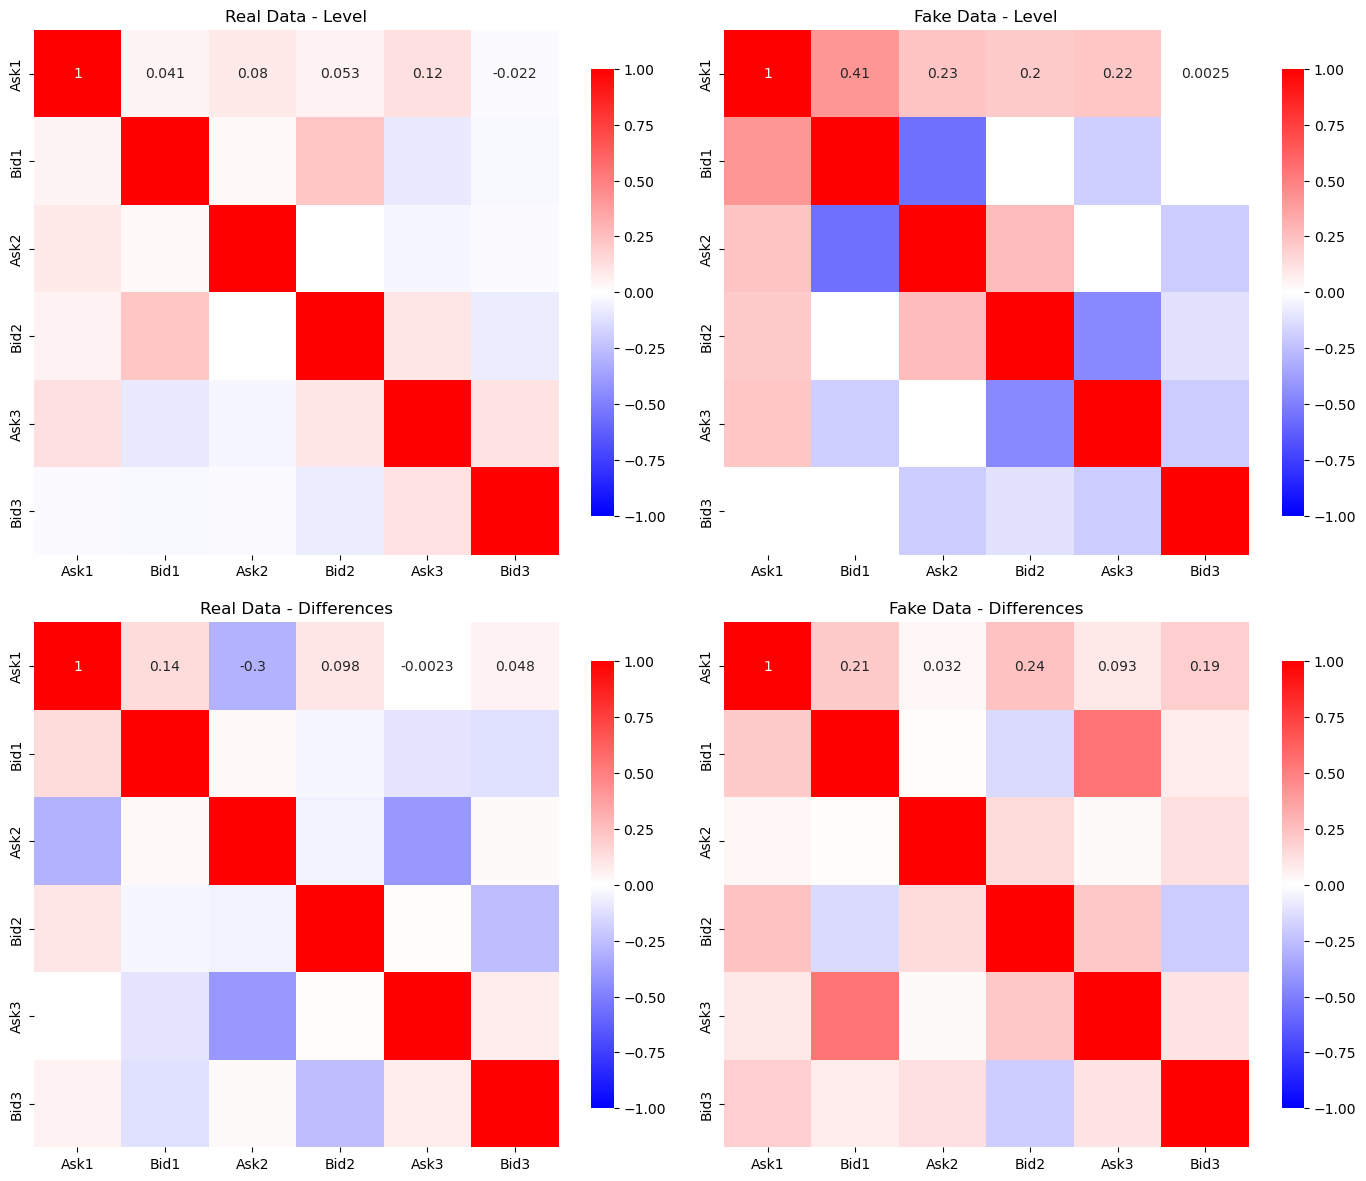

In [41]:
# --- 1. PREPARE DATA & REORDER COLUMNS ---
# Our current state vector order: [Bid3(0), Bid2(1), Bid1(2), Ask1(3), Ask2(4), Ask3(5)]
# The paper's visualization order: [Ask1(3), Bid1(2), Ask2(4), Bid2(1), Ask3(5), Bid3(0)]
reorder_idx = [3, 2, 4, 1, 5, 0]
tick_labels = ['Ask1', 'Bid1', 'Ask2', 'Bid2', 'Ask3', 'Bid3']

# Apply the reordering to our denormalized Level data
real_levels = real_X[:, reorder_idx]
fake_levels = fake_X[:, reorder_idx]

# To calculate Differences (Increments), we need the denormalized initial states (S_t)
real_S = denormalize(test_S.numpy())
real_S_reordered = real_S[:, reorder_idx]

# Calculate Increments: X_{t+dt} - X_t
real_diff = real_levels - real_S_reordered
fake_diff = fake_levels - real_S_reordered

# --- 2. CALCULATE CORRELATION MATRICES ---
# Using Pandas to easily compute Pearson correlation matrices with column names attached
corr_real_levels = pd.DataFrame(real_levels, columns=tick_labels).corr()
corr_fake_levels = pd.DataFrame(fake_levels, columns=tick_labels).corr()
corr_real_diff = pd.DataFrame(real_diff, columns=tick_labels).corr()
corr_fake_diff = pd.DataFrame(fake_diff, columns=tick_labels).corr()

# --- 3. PLOT THE HEATMAPS ---
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Standardize heatmap settings to match the paper's aesthetic
heatmap_kwargs = {
    'annot': True,          # Show the correlation values
    'cmap': 'bwr',          # Blue-White-Red colormap
    'vmin': -1,             # Minimum correlation
    'vmax': 1,              # Maximum correlation
    'fmt': ".2g",           # Show 2 significant digits
    'square': True,         # Force square cells
    'cbar_kws': {"shrink": .8}
}

# Top-Left: Real Data - Level
sns.heatmap(corr_real_levels, ax=axes[0, 0], **heatmap_kwargs)
axes[0, 0].set_title('Real Data - Level')

# Top-Right: Fake Data - Level
sns.heatmap(corr_fake_levels, ax=axes[0, 1], **heatmap_kwargs)
axes[0, 1].set_title('Fake Data - Level')

# Bottom-Left: Real Data - Differences
sns.heatmap(corr_real_diff, ax=axes[1, 0], **heatmap_kwargs)
axes[1, 0].set_title('Real Data - Differences')

# Bottom-Right: Fake Data - Differences
sns.heatmap(corr_fake_diff, ax=axes[1, 1], **heatmap_kwargs)
axes[1, 1].set_title('Fake Data - Differences')

# Adjust layout and display
plt.tight_layout()
plt.show()